# Closing the Loop
### Automated Structure-Performance Data Pipelines for AI-Guided Materials Research


### Define environment variable

In [1]:
import os
from dotenv import find_dotenv, load_dotenv
# from girder_client import GirderClient

load_dotenv(find_dotenv())

# os.environ["GIRDER_API_KEY"] = ''
# print(os.environ["GIRDER_API_KEY"])

True

In [2]:
import sys
from pathlib import Path

import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd().parent / 'src'))
from aimdl_examples import (
    get_girder_client,
    fetch_and_parse,
    coerce_types,
    paginate_datafiles,
    enrich_alpss_with_material_properties,
)

from matplotlib.pyplot import ylim
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## Fetch Results

Query all `pdv_alpss_result` items from the API, parse each CSV file, and combine into a single DataFrame.

In [3]:
with requests.Session() as session:
    gc = get_girder_client(session=session)
    rows = paginate_datafiles(
        gc,
        "pdv_alpss_result",
        lambda item: fetch_and_parse(gc, item),
        extraFields='["meta.prov", "meta.runId"]'
    )

    df = pd.DataFrame(rows)
    df = coerce_types(df)

In [ ]:
# Add material properties from the entry form
df = enrich_alpss_with_material_properties(df, gc)

print(f"Added material property columns:")
print(f"  material_c0: {df['material_c0'].notna().sum()} / {len(df)} rows")
print(f"  material_c_l: {df['material_c_l'].notna().sum()} / {len(df)} rows")
print(f"  material_density: {df['material_density'].notna().sum()} / {len(df)} rows")
print(f"  material_type: {df['material_type'].notna().sum()} / {len(df)} rows")
print(f"  material_thickness: {df['material_thickness'].notna().sum()} / {len(df)} rows")

Added material property columns:
  material_c0: 1977 / 3363 rows
  material_c_l: 1977 / 3363 rows
  material_density: 1977 / 3363 rows
  material_type: 1977 / 3363 rows
  material_thickness: 0 / 3363 rows


In [4]:
# Convert to GPa
spall_col = 'Spall Strength'
divide_by = 1e9
spall_col_gpa = 'Spall Strength (GPa)'
df[spall_col_gpa] = df[spall_col] / divide_by


## Enrich with material properties

Query the material properties form and add columns for c0, c_l, and density.

### Data Overview

Each row is one shock experiment result. Example of columns:
- **`igsn`** — Sample identifier
- **`Velocity OK`** — Whether the velocity computation step passed quality checks (True/False)
- **`Velocity at Max Compression`** — Peak velocity (m/s)
- **`Spall OK`, `Spall Strength`, `Strain Rate`** - Spall quality check and derived metrics
- **`HEL OK`,`HEL Strength (GPa)`, `HEL Free Surface Velocity`** - HEL quality check and derived metrics
- Uncertainty columns (e.g., `Velocity at Max Compression Vel Uncertainty`, `Spall Strength Uncertainty`) quantify measurement error
- **`alpss_version`, `alpss_dagster_version`** — Processing pipeline versions

In [5]:
print(f"Total results: {len(df)}")
print(f"Columns: {len(df.columns)}")
print(f"\nShape: {df.shape}")

Total results: 3363
Columns: 44

Shape: (3363, 44)


## Sanity checks

In [6]:
# Statistics for rows that contain a valid spall strength measurement.

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# Keep only rows where the spall strength column is present.
spall_col = 'Spall Strength'
df_spall = df[df[spall_col].notna()].copy()

# If a quality flag exists, report how many spall measurements also pass it.
spall_ok_col = 'Spall OK'
if spall_ok_col in df_spall.columns:
    df_spall_ok = df_spall[df_spall[spall_ok_col] == True].copy()
    print(f"Rows with valid '{spall_col}' and '{spall_ok_col}' == True: {len(df_spall_ok)} / {len(df)}")
else:
    df_spall_ok = df_spall.copy()
    print(f"No '{spall_ok_col}' column found; using all valid spall rows.")


# Descriptive statistics for the complete spall-strength subset.
display(df_spall[spall_col].describe())

# A compact summary of the associated spall metadata.
summary_cols = [c for c in [spall_col, 'Strain Rate', 'Velocity at Max Tension', 'Time at Max Tension', 'Time at Recompression', 'igsn'] if c in df_spall.columns]
print(summary_cols)

# display(df_spall[summary_cols].describe().T)
print(df_spall[summary_cols].describe().T.to_string())




Rows with valid 'Spall Strength' and 'Spall OK' == True: 552 / 3363


count    5.520000e+02
mean     2.323555e+09
std      1.594244e+09
min      2.228620e+07
25%      1.009985e+09
50%      2.339179e+09
75%      3.459566e+09
max      1.662609e+10
Name: Spall Strength, dtype: float64

['Spall Strength', 'Strain Rate', 'Velocity at Max Tension', 'Time at Max Tension', 'Time at Recompression', 'igsn']
                         count          mean           std           min           25%           50%           75%           max
Spall Strength           552.0  2.323555e+09  1.594244e+09  2.228620e+07  1.009985e+09  2.339179e+09  3.459566e+09  1.662609e+10
Strain Rate              552.0  1.142081e+06  2.282245e+06  6.892223e+04  5.000687e+05  7.605560e+05  1.232444e+06  4.708460e+07
Velocity at Max Tension  552.0  9.276936e+01  6.970861e+01 -6.528581e+02  5.762014e+01  8.972861e+01  1.225851e+02  4.191587e+02
Time at Max Tension      552.0  1.277581e-06  4.580657e-07  1.592500e-08  9.425137e-07  1.330172e-06  1.651543e-06  1.992984e-06
Time at Recompression    552.0  1.281629e-06  4.566162e-07  3.295000e-08  9.475820e-07  1.335469e-06  1.658557e-06  1.997055e-06


In [7]:
# Show the strongest and weakest spall-strength measurements for quick sanity checks.
display(df_spall.sort_values(spall_col, ascending=False)[summary_cols + (['igsn'] if 'igsn' in df_spall.columns else [])].head(3))
display(df_spall.sort_values(spall_col, ascending=True)[summary_cols + (['igsn'] if 'igsn' in df_spall.columns else [])].head(3))

# tmp = df_spall.sort_values(spall_col, ascending=False)[summary_cols].head(10)
# print(tmp.shape)
# print(tmp)
#
# tmp = df_spall.sort_values(spall_col, ascending=True)[summary_cols].head(10)
# print(tmp.shape)
# print(tmp)



,Spall Strength,Strain Rate,Velocity at Max Tension,Time at Max Tension,Time at Recompression,igsn,igsn
2759,1.662609e+10,4.708460e+07,69.386975,1.143047e-06,1.146305e-06,JHAMAL00016-012,JHAMAL00016-012
1163,8.576346e+09,2.781962e+06,-652.858147,5.627500e-08,6.892500e-08,JHAMAL00016-015,JHAMAL00016-015
1168,7.618579e+09,3.511977e+06,-12.064359,4.085000e-08,5.535000e-08,JHAMAL00016-015,JHAMAL00016-015


,Spall Strength,Strain Rate,Velocity at Max Tension,Time at Max Tension,Time at Recompression,igsn,igsn
2774,2.228620e+07,69117.361913,67.462914,0.000002,0.000002,JHAMAL00016-013,JHAMAL00016-013
855,3.023009e+07,68922.231079,104.112284,0.000002,0.000002,JHAMAB00020-10,JHAMAB00020-10
483,3.444023e+07,206534.064988,76.787353,0.000002,0.000002,JHAMAB00020-04,JHAMAB00020-04


In [8]:
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

0: Date
1: File Name
2: Run Time
3: Error Message
4: Velocity OK
5: Velocity at Max Compression
6: Time at Max Compression
7: Velocity at Max Compression Freq Uncertainty
8: Velocity at Max Compression Vel Uncertainty
9: Carrier Frequency
10: Spect Time Res
11: Spect Freq Res
12: Spect Velocity Res
13: Signal Start Time
14: Smoothing Characteristic Time
15: Spall Enabled
16: Spall OK
17: Velocity at Max Tension
18: Time at Max Tension
19: Velocity at Max Tension Freq Uncertainty
20: Velocity at Max Tension Vel Uncertainty
21: Velocity at Recompression
22: Time at Recompression
23: Spall Strength
24: Strain Rate
25: Uncertainty OK
26: Spall Strength Uncertainty
27: Strain Rate Uncertainty
28: HEL Enabled
29: HEL OK
30: HEL Strength (GPa)
31: HEL Uncertainty (GPa)
32: HEL Free Surface Velocity (m/s)
33: HEL Time Detection (ns)
34: HEL Consecutive Points
35: HEL Segment Duration (ns)
36: HEL Strain Rate
37: Peak Shock Stress
38: igsn
39: itemId
40: runId
41: alpss_dagster_version
42: alps

### Define plot

In [9]:
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, MaxNLocator

# --- Matplotlib global settings ---
mpl.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'font.serif': ['STIXGeneral'],
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': False,
    'figure.figsize': (6.0, 4.0),
    'legend.frameon': False,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
})

plt.rcParams.update({
    'legend.frameon': True,
    'legend.facecolor': 'white',
    'legend.edgecolor': 'grey',
    'legend.framealpha': 1.0,
    'legend.fancybox': False,
    'legend.handlelength': 2.0,
    'legend.labelspacing': 0.3,
    'legend.handletextpad': 0.3,
})


## Correlation study


Physically meaningful correlations with Spall Strength:


,Pearson r
Velocity at Max Compression,0.869831
Peak Shock Stress,0.830811
Strain Rate,0.436258
Velocity at Max Tension,-0.220156
Velocity at Recompression,0.170806
HEL Strain Rate,-0.064174
HEL Strength (GPa),0.028339


plot saved as: spall_strength_physics_correlation_matrix_v1.pdf


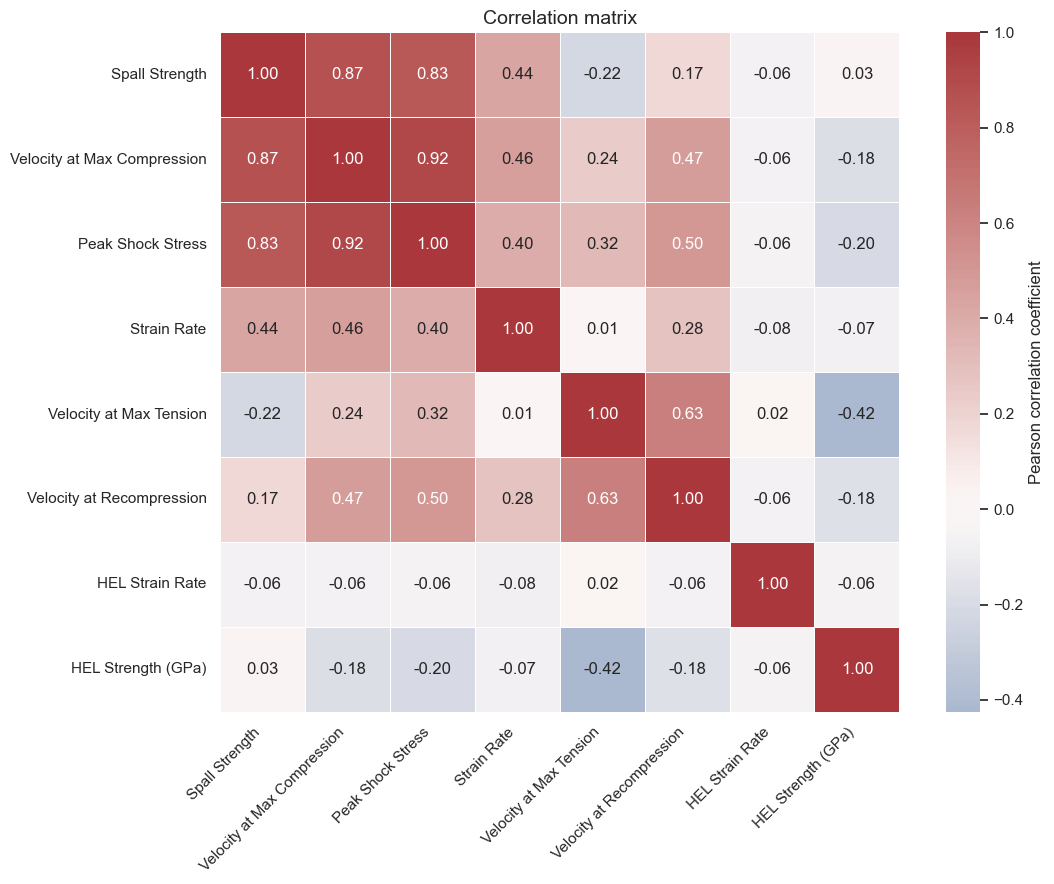

In [10]:
# Correlation analysis focused on spall strength.
# Goal: identify numeric quantities strongly correlated with spall strength, then visualize those relationships.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

spall_col = 'Spall Strength'

df_spall = df[df[spall_col].notna()].copy()

# -----------------------------
# Physically meaningful variables
# -----------------------------
physics_cols = [
    'Spall Strength',
    'Strain Rate',
    'HEL Strength (GPa)',
    'HEL Strain Rate',
    'Peak Shock Stress',
    'material_thickness',
    'material_density',
    'material_c0',
    'material_c_l',
    'Velocity at Max Compression',
    'Velocity at Max Tension',
    'Velocity at Recompression',
]

# Keep only columns that exist
physics_cols = [c for c in physics_cols if c in df_spall.columns]

numeric_df = df_spall[physics_cols].select_dtypes(include='number').copy()

# Remove columns with no variation
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

# -----------------------------
# Correlation with spall strength
# -----------------------------
corr_matrix = numeric_df.corr(method='pearson')

corr_with_spall = (
    corr_matrix[spall_col]
    .dropna()
    .drop(index=spall_col, errors='ignore')
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print('Physically meaningful correlations with Spall Strength:')
display(corr_with_spall.to_frame(name='Pearson r'))

# -----------------------------
# More informative heatmap
# -----------------------------
ordered_cols = [spall_col] + corr_with_spall.index.tolist()
corr_matrix_ordered = numeric_df[ordered_cols].corr(method='pearson')

fig, ax = plt.subplots(
    figsize=(1.2 * len(ordered_cols) + 2, 1.0 * len(ordered_cols) + 1)
)

sns.heatmap(
    corr_matrix_ordered,
    annot=True,
    fmt='.2f',
    cmap='vlag',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson correlation coefficient'},
    ax=ax
)

ax.set_title('Correlation matrix', fontsize=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()

filename_1 = "spall_strength_physics_correlation_matrix_v1.pdf"
plt.savefig(filename_1, bbox_inches="tight")
print(f"plot saved as: {filename_1}")

plt.show()

In [11]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df_spall,
    x='Strain Rate',
    y='Spall Strength (GPa)',
    hue='material_type'
)

filename_1 = "spall_vs_strain_rate_v1.pdf"
plt.savefig(filename_1, bbox_inches="tight")
print(f"plot saved as: {filename_1}")

plt.xscale('log')

ValueError: Could not interpret value `material_type` for `hue`. An entry with this name does not appear in `data`.

<Figure size 700x500 with 0 Axes>

plot saved as: spall_vs_HEL_v1.pdf


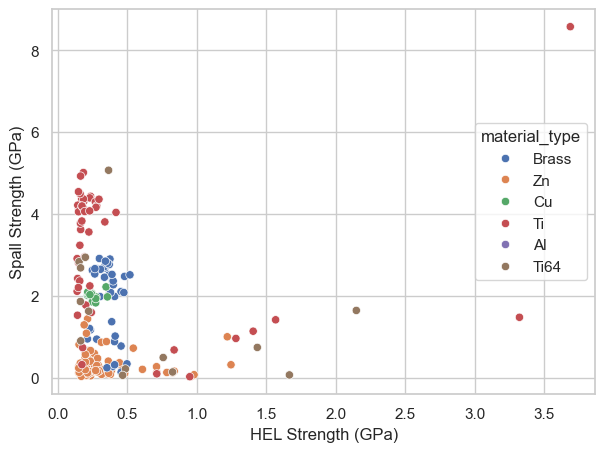

In [ ]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df_spall,
    x='HEL Strength (GPa)',
    y='Spall Strength (GPa)',
    hue='material_type'
)

filename_1 = "spall_vs_HEL_v1.pdf"
plt.savefig(filename_1, bbox_inches="tight")
print(f"plot saved as: {filename_1}")


## Uncertainty evolution and dynamic box plots


Removed 5 extreme outlier points
Material column used for grouping: material_type
Unique materials plotted: 6


NameError: name 'MaxNLocator' is not defined

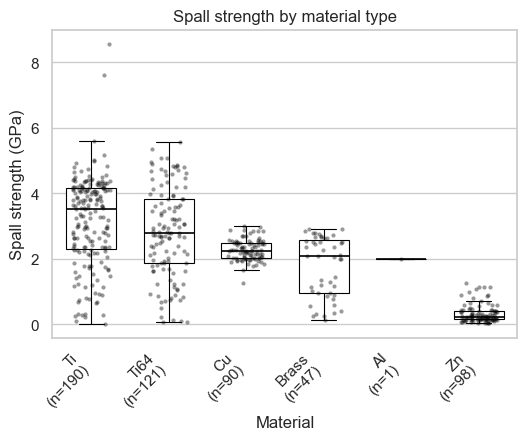

In [ ]:
# --- Spall-strength box plot by material type ---


boxprops=dict(facecolor='white', edgecolor='black', linewidth=0.8)
medianprops=dict(color='black', linewidth=1.2)
whiskerprops=dict(color='black', linewidth=0.8)
capprops=dict(color='black', linewidth=0.8)


spall_col = 'Spall Strength'
material_candidates = ['material_type', 'igsn']


# Add strain rate column name
strain_rate_col = 'Strain Rate'




df_spall = df[df[spall_col].notna()].copy()

material_col = next((c for c in material_candidates if c in df_spall.columns), None)

if material_col is None:
    raise KeyError('No material-like column was found. Expected one of: ' + ', '.join(material_candidates))

# plot_df = df_spall[[material_col, 'igsn', spall_col_gpa]].copy()
plot_df = df_spall[[material_col, 'igsn', spall_col_gpa, strain_rate_col]].copy()


plot_df[material_col] = plot_df[material_col].astype(str).str.strip()
plot_df = plot_df[
    plot_df[material_col].notna()
    & (plot_df[material_col] != '')
    & (plot_df[material_col].str.lower() != 'nan')
]

n_before = len(plot_df)

# IQR filtering here
# remove extreme outliers using group-wise 3.0*IQR rule
q1 = plot_df.groupby(material_col)[spall_col_gpa].transform(lambda x: x.quantile(0.25))
q3 = plot_df.groupby(material_col)[spall_col_gpa].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
plot_df = plot_df[
    (plot_df[spall_col_gpa] >= q1 - 3.0 * iqr) &
    (plot_df[spall_col_gpa] <= q3 + 3.0 * iqr)
]
n_after = len(plot_df)
print(f"Removed {n_before - n_after} extreme outlier points")


order = (
    plot_df.groupby(material_col)[spall_col_gpa]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)



# # remove material with very few points
# keep_materials = counts[counts >= 5].index
# plot_df = plot_df[plot_df[material_col].isin(keep_materials)]

counts = plot_df[material_col].value_counts()

xtick_labels = [f"{m}\n(n={counts[m]})" for m in order]


print(f"Material column used for grouping: {material_col}")
print(f"Unique materials plotted: {len(order)}")

fig_width = max(6.0, 0.45 * len(order))
fig, ax = plt.subplots(figsize=(fig_width, 4.0))

sns.boxplot(
    data=plot_df,
    x=material_col,
    y=spall_col_gpa,
    order=order,
    width=0.65,
    showfliers=False,
    ax=ax,

    boxprops=boxprops,

    medianprops=medianprops,

    whiskerprops=whiskerprops,

    capprops=capprops,
)

### Plot the strip points
sns.stripplot(
    data=plot_df,
    x=material_col,
    y=spall_col_gpa,
    order=order,
    color='black',
    size=3.0,
    alpha=0.4,
    jitter=0.24,
    ax=ax
)

# # Plot the strip points colored by strain rate
# # Note: We use palette='viridis' (or 'plasma', 'magma', 'inferno') for continuous data
# stripplot = sns.stripplot(
#     data=plot_df,
#     x=material_col,
#     y=spall_col_gpa,
#     order=order,
#     hue=strain_rate_col,
#     palette='viridis',
#     size=4.0,               # Bumped up slightly so colors are easier to see
#     alpha=0.7,              # Slightly higher alpha to make colors pop
#     jitter=0.24,
#     ax=ax
# )

# # Remove the auto-generated legend
# ax.get_legend().remove()
#
# # Create continuous colorbar
# norm = plt.Normalize(plot_df[strain_rate_col].min(), plot_df[strain_rate_col].max())
# sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
# sm.set_array([])
#
# # Append the colorbar to the plot
# cbar = fig.colorbar(sm, ax=ax, pad=0.02)
# cbar.set_label('Strain Rate ($s^{-1}$)') # Adjust unit as necessary



ax.set_title('Spall strength by material type')
ax.set_xlabel('Material')
ax.set_ylabel('Spall strength (GPa)')

ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels(xtick_labels, rotation=45, ha='right')

ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.grid(True, linestyle='--', alpha=0.25, zorder=0)

ymax = plot_df[spall_col_gpa].max()
ymax_nice = np.ceil(ymax * 2) / 2

ax.set_ylim(0, ymax_nice)

plt.tight_layout()

filename_1 = "spall_vs_material_type_GPa.pdf"
plt.savefig(filename_1, bbox_inches="tight")
print(f"plot saved as: {filename_1}")


plt.show()
plot_df_static = plot_df.copy()


In [14]:
# --- Spall-strength box plot by material type and colored by strain rate---

import matplotlib.colors as mcolors


boxprops=dict(facecolor='white', edgecolor='black', linewidth=0.8)
medianprops=dict(color='black', linewidth=1.2)
whiskerprops=dict(color='black', linewidth=0.8)
capprops=dict(color='black', linewidth=0.8)


spall_col = 'Spall Strength'
material_candidates = ['material_type', 'igsn']


# Add strain rate column name
strain_rate_col = 'Strain Rate'




df_spall = df[df[spall_col].notna()].copy()

material_col = next((c for c in material_candidates if c in df_spall.columns), None)

if material_col is None:
    raise KeyError('No material-like column was found. Expected one of: ' + ', '.join(material_candidates))

# plot_df = df_spall[[material_col, 'igsn', spall_col_gpa]].copy()
plot_df = df_spall[[material_col, 'igsn', spall_col_gpa, strain_rate_col]].copy()


plot_df[material_col] = plot_df[material_col].astype(str).str.strip()
plot_df = plot_df[
    plot_df[material_col].notna()
    & (plot_df[material_col] != '')
    & (plot_df[material_col].str.lower() != 'nan')
]

n_before = len(plot_df)

# IQR filtering here
# remove extreme outliers using group-wise 3.0*IQR rule
q1 = plot_df.groupby(material_col)[spall_col_gpa].transform(lambda x: x.quantile(0.25))
q3 = plot_df.groupby(material_col)[spall_col_gpa].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
plot_df = plot_df[
    (plot_df[spall_col_gpa] >= q1 - 3.0 * iqr) &
    (plot_df[spall_col_gpa] <= q3 + 3.0 * iqr)
]
n_after = len(plot_df)
print(f"Removed {n_before - n_after} extreme outlier points")


order = (
    plot_df.groupby(material_col)[spall_col_gpa]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)



# # remove material with very few points
# keep_materials = counts[counts >= 5].index
# plot_df = plot_df[plot_df[material_col].isin(keep_materials)]

counts = plot_df[material_col].value_counts()

xtick_labels = [f"{m}\n(n={counts[m]})" for m in order]


print(f"Material column used for grouping: {material_col}")
print(f"Unique materials plotted: {len(order)}")

fig_width = max(6.0, 0.45 * len(order))
fig, ax = plt.subplots(figsize=(fig_width, 4.0))

sns.boxplot(
    data=plot_df,
    x=material_col,
    y=spall_col_gpa,
    order=order,
    width=0.65,
    showfliers=False,
    ax=ax,

    boxprops=boxprops,

    medianprops=medianprops,

    whiskerprops=whiskerprops,

    capprops=capprops,
)

# Plot the strip points
# sns.stripplot(
#     data=plot_df,
#     x=material_col,
#     y=spall_col_gpa,
#     order=order,
#     color='black',
#     size=3.0,
#     alpha=0.4,
#     jitter=0.24,
#     ax=ax
# )


# Plot the strip points using a logarithmic color mapping
stripplot = sns.stripplot(
    data=plot_df,
    x=material_col,
    y=spall_col_gpa,
    order=order,
    hue=strain_rate_col,
    palette='viridis',
    hue_norm=mcolors.LogNorm(vmin=1e5, vmax=1e7), # Sets log scale on the points
    size=4.0,
    alpha=0.7,
    jitter=0.24,
    ax=ax
)

# Remove the automatic categorical legend
ax.get_legend().remove()

# Create a continuous logarithmic colorbar
norm = mcolors.LogNorm(vmin=1e5, vmax=1e7)
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])

# Append the colorbar to the plot
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Strain Rate ($s^{-1}$)')

ax.set_title('Spall strength by material type')
ax.set_xlabel('Material')
ax.set_ylabel('Spall strength (GPa)')

ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels(xtick_labels, rotation=45, ha='right')

ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.grid(True, linestyle='--', alpha=0.25, zorder=0)

ymax = plot_df[spall_col_gpa].max()
ymax_nice = np.ceil(ymax * 2) / 2

ax.set_ylim(0, ymax_nice)

plt.tight_layout()

filename_1 = "spall_vs_material_type_strain_rate_v1.pdf"
plt.savefig(filename_1, bbox_inches="tight")
print(f"plot saved as: {filename_1}")


plt.show()
plot_df_static = plot_df.copy()


AttributeError: 'DataFrame' object has no attribute 'str'

In [13]:
### Dynamic gif updating the box plot as new IGSNs are added
# Goal: study evolution of uncertainty with number of experiments


from matplotlib.animation import FuncAnimation, PillowWriter


igsn_col = 'igsn'

# Use static plot ordering and labels
# static_order = order.copy()

static_order = (
    plot_df_static.groupby(material_col)[spall_col_gpa]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

# Fixed full x-axis and y-axis from static plot
static_counts = plot_df_static[material_col].value_counts()
static_xtick_labels = [f"{m}\n(n={static_counts[m]})" for m in static_order]

ymax = plot_df_static[spall_col_gpa].max() * 1.05
ymax_nice = np.ceil(ymax * 2) / 2

fig_width = max(6.0, 0.45 * len(static_order))
fig, ax = plt.subplots(figsize=(fig_width, 4.0))

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.28,
    top=0.90
)


# Assign each point a fixed jittered x position ONCE, before frames are built.
# Every frame_df is a slice of plot_df_static, so these columns must already
# exist -- and the jitter must be stable across frames so points don't twitch.
rng = np.random.default_rng(10)

plot_df_static = plot_df_static.copy()
plot_df_static['_xbase'] = plot_df_static[material_col].map(
    {m: i for i, m in enumerate(static_order)}
)
plot_df_static['_xjitter'] = plot_df_static['_xbase'] + rng.uniform(
    -0.18, 0.18, size=len(plot_df_static)
)

# Build cumulative frames:
# material 1 grows IGSN-by-IGSN, then material 2 pops in and grows, etc.
frames = []
current_igsns = []

for mat in static_order:
    mat_df = plot_df_static[plot_df_static[material_col] == mat].copy()

    igsn_order = mat_df[igsn_col].drop_duplicates().tolist()

    for igsn in igsn_order:
        current_igsns.append(igsn)

        frame_df = plot_df_static[plot_df_static[igsn_col].isin(current_igsns)].copy()

        frames.append({
            'material': mat,
            'igsn': igsn,
            'frame_df': frame_df
        })

def update(frame_id):
    ax.clear()

    if frame_id >= len(frames):
        return

# def update(frame_id):
#     ax.clear()

    frame_info = frames[frame_id]
    frame_df = frame_info['frame_df']
    current_material = frame_info['material']
    current_igsn = frame_info['igsn']

    current_counts = frame_df[material_col].value_counts()

    # Dynamic labels show current n, not final n
    xtick_labels = [
        f"{m}\n(n={current_counts.get(m, 0)})"
        for m in static_order
    ]

    sns.boxplot(
        data=frame_df,
        x=material_col,
        y=spall_col_gpa,
        order=static_order,
        width=0.65,
        showfliers=False,
        ax=ax,
        boxprops=boxprops,
        medianprops=medianprops,
        whiskerprops=whiskerprops,
        capprops=capprops,
    )

    ax.scatter(
    frame_df['_xjitter'],
    frame_df[spall_col_gpa],
    color='black',
    s=9,
    alpha=0.4,
    zorder=10,
    clip_on=False
    )

    ax.set_title(
        f'Adding material: {current_material} | IGSN: {current_igsn}',
        pad=8
    )

    ax.set_xlabel('Material')
    ax.set_ylabel('Spall strength (GPa)')

    ax.set_xticks(np.arange(len(static_order)))
    ax.set_xticklabels(xtick_labels, rotation=45, ha='right')

    ax.set_xlim(-0.5, len(static_order) - 0.5)
    ax.set_ylim(0, ymax_nice)

    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(True, linestyle='--', alpha=0.25, zorder=0)

    # plt.tight_layout()


print("Number of frames:", len(frames))
print("Number of rows in plot_df_static:", len(plot_df_static))
print("Unique IGSNs:", plot_df_static[igsn_col].nunique())
print("Unique materials:", plot_df_static[material_col].nunique())

frame_ids = list(range(len(frames)))

ani = FuncAnimation(
    fig,
    update,
    frames=frame_ids,
    interval=700,
    repeat=True
)


filename_gif = "spall_material_type_igsn_growth_v1.gif"
# ani.save(filename_gif, writer=PillowWriter(fps=1.5))
ani.save(
    filename_gif,
    writer=PillowWriter(fps=1.5),
    dpi=150
)

print(f"animation saved as: {filename_gif}")

plt.show()



NameError: name 'plot_df_static' is not defined